# 277. SCOPe40 family and superfamily sensitivity with kmerseek 0.4: 19 alphabets, k_min to k_max, six settings

**Data.** The SCOPe40 sweep of
[PR 107](https://github.com/seanome/2024-kmerseek-analysis/pull/107)
(`nextflow-runs/scope40-alphabet-ksize-v040`), run on Sherlock from 2026-10-10 10:36 to
2026-10-12 07:53 (head job 46668151), image `olgabot/kmerseek:0.4.0-rc5` (kmerseek 0.4.0).
Query set and target database are the same: the 15_177 SCOPe 2.08 domains at 40% identity
(`astral-scopedom-seqres-gd-sel-gs-bib-40-2.08.fa`), searched all against all. 19 alphabets,
each at every k from its k_min to its k_max in
[notebook 274](https://github.com/seanome/2024-kmerseek-analysis/pull/101) (229
alphabet-ksize pairs), each with six settings: `exact` (no extension) and extension with
mismatch penalty C at `c_min`, 1.1 x `c_min`, `c_opt`, `c_max` and C = 2. The PR body defines
each C. That is 1_358 searches; all 1_358 finished. The table read here is the pipeline's
`scope40_v040_auc.tsv`, one row per search, score column and SCOP level.

**What is measured.** For each query, hits are ranked by one kmerseek score column.
Sensitivity is the share of that query's true positives ranked above its first false positive,
with FoldSeek's rule: a hit in a different fold is a false positive, and a hit in the same fold
but a different superfamily is ignored. The AUC is the mean of that share over queries
(higher is better; 1 means every true positive ranks above every false positive, 0 means none
does). This notebook uses `auc_ref`: the AUC over FoldSeek's 5_713 SCOPe40 queries, where a
query kmerseek returns no hit for counts as 0, so every tool has the same denominator.
Family level: true positive = same SCOP family. Superfamily level: same superfamily,
different family.

**Other tools, same 5_713 queries** (TEA paper's `.rocx` files in `data/tea_scope40_rocx_files`):
FoldSeek (structure) and MMseqs2 (sequence).

**Decisions this notebook makes.** These were written after a first look at the 15 highest
family AUCs, not before any result.

1. *Which score column the SCOPe40 figures rank by.* The column with the highest median family
   AUC across the extension searches, provided that tied scores do not move its AUC (median
   difference between the two tie orders is 0).
2. *Which mismatch penalty C to run by default.* The setting that gives the best family AUC for
   the most alphabets.
3. *Whether the k range must go lower.* If the best k sits at the alphabet's k_min for most
   alphabets, sensitivity may still be rising at the bottom of the range, and the sweep has to
   extend below k_min before any "best k" is quoted. Section 6 runs that test.
4. *Whether SCOPe40 supports the hydrophobic-polar (HP) alphabets.* If the best HP family AUC
   reaches half of MMseqs2's, SCOPe40 goes in the paper as support for HP; otherwise the HP
   case is made on the domain benchmarks, and SCOPe40 is reported for protein20 and the
   larger alphabets only.

In [1]:
import hashlib
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import pubfig as pf
import scope_kmerseek_utils as su

pf.use_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_float_precision(3)

AUC_TSV = Path(
    os.environ.get(
        "NB277_AUC_TSV",
        Path.home()
        / "data/scope/results-scope40-alphabet-ksize-v040/scope40_v040_auc.tsv",
    )
)
FIG_DIR = Path("../figures")
FIG_STEM = "277_scope40_kmerseek_v040"
LEVELS = ["family", "superfamily"]
EXTENSION_SETTINGS = ["c_min", "c_min_x1.1", "c_opt", "c_max", "c2"]
SETTINGS = ["exact"] + EXTENSION_SETTINGS
SETTING_LABEL = {
    "exact": "exact (no extension)",
    "c_min": "C = c_min",
    "c_min_x1.1": "C = 1.1 x c_min",
    "c_opt": "C = c_opt",
    "c_max": "C = c_max",
    "c2": "C = 2",
}
SETTING_COLOUR = {
    "exact": pf.OKABE_ITO["black"],
    "c_min": pf.OKABE_ITO["sky_blue"],
    "c_min_x1.1": pf.OKABE_ITO["blue"],
    "c_opt": pf.OKABE_ITO["bluish_green"],
    "c_max": pf.OKABE_ITO["vermillion"],
    "c2": pf.OKABE_ITO["orange"],
}
TOOL_STYLE = {  # other tools: vertical lines, never a colour used by a kmerseek setting
    "FoldSeek": dict(color=pf.GREY, ls="-", lw=1),
    "MMseqs2": dict(color=pf.GREY, ls="--", lw=1),
}
TOOL_ROCX = {"FoldSeek": "foldseek.rocx", "MMseqs2": "mmseqs.rocx"}

print(AUC_TSV)
print("sha256", hashlib.sha256(AUC_TSV.read_bytes()).hexdigest())
auc = pl.read_csv(AUC_TSV, separator="\t")
print(auc.shape)

/Users/olga/data/scope/results-scope40-alphabet-ksize-v040/scope40_v040_auc.tsv
sha256 c9a30b83d6c0a064b79f629c0fe921d6366d3b14b9d801cb06101077319101af
(55008, 19)


In [2]:
def alphabet_size(name: str) -> int:
    """Number of letters, the trailing number of the alphabet name (hp_thomas_dill2 -> 2)."""
    return int(re.search(r"(\d+)$", name).group(1))


def size_group(n: int) -> str:
    """Alphabet size group used to order every alphabet axis."""
    if n <= 3:
        return "2-3 letters"
    if n <= 8:
        return "4-8 letters"
    if n <= 18:
        return "12-18 letters"
    return "20 letters"


GROUP_ORDER = ["2-3 letters", "4-8 letters", "12-18 letters", "20 letters"]
ALPHABETS = sorted(
    auc["alphabet"].unique(),
    key=lambda a: (
        GROUP_ORDER.index(size_group(alphabet_size(a))),
        alphabet_size(a),
        a,
    ),
)


def alphabet_positions(alphabets, gap=0.8):
    """y position per alphabet, with a blank gap between size groups (top to bottom)."""
    pos, y, prev = {}, 0.0, None
    for a in alphabets:
        g = size_group(alphabet_size(a))
        if prev is not None and g != prev:
            y += gap
        pos[a] = y
        y += 1
        prev = g
    return pos


def alphabet_axis(ax, pos):
    """Alphabet names on y, grouped by size, guide lines from each tick across the panel."""
    ax.set_yticks(list(pos.values()), list(pos.keys()))
    ax.set_ylim(max(pos.values()) + 0.7, -0.7)
    for y in pos.values():
        ax.axhline(y, color="0.9", lw=0.3, zorder=0)


ks = (
    auc.select("alphabet", "ksize")
    .unique()
    .group_by("alphabet")
    .agg(
        pl.col("ksize").min().alias("k_min"),
        pl.col("ksize").max().alias("k_max"),
        pl.len().alias("n_ksizes"),
    )
)
print(
    ks.sort(pl.col("alphabet").replace_strict({a: i for i, a in enumerate(ALPHABETS)}))
)

shape: (19, 4)
┌──────────────────────────┬───────┬───────┬──────────┐
│ alphabet                 ┆ k_min ┆ k_max ┆ n_ksizes │
│ ---                      ┆ ---   ┆ ---   ┆ ---      │
│ str                      ┆ i64   ┆ i64   ┆ u32      │
╞══════════════════════════╪═══════╪═══════╪══════════╡
│ hp_kyte_doolittle2       ┆ 19    ┆ 39    ┆ 21       │
│ hp_lehninger2            ┆ 17    ┆ 30    ┆ 14       │
│ hp_lehninger_c_nonpolar2 ┆ 17    ┆ 31    ┆ 15       │
│ hp_pbotc_1st_ed2         ┆ 17    ┆ 30    ┆ 14       │
│ hp_thomas_dill2          ┆ 18    ┆ 36    ┆ 19       │
│ hp_thomas_dill_no_c2     ┆ 18    ┆ 39    ┆ 22       │
│ hp_lehninger_hpc3        ┆ 17    ┆ 29    ┆ 13       │
│ gbmr4                    ┆ 13    ┆ 28    ┆ 16       │
│ polarity4                ┆ 11    ┆ 25    ┆ 15       │
│ wwmj5                    ┆ 9     ┆ 15    ┆ 7        │
│ dayhoff6                 ┆ 8     ┆ 18    ┆ 11       │
│ gbmr7                    ┆ 13    ┆ 35    ┆ 23       │
│ funcgroups8              ┆ 7   

In [3]:
# Other tools on the same 5_713 FoldSeek queries, with the same AUC function the pipeline uses.
ref_queries = set(su.load_rocx_file(su.TEA_DIR / "foldseek.rocx")["NAME"])
tool_rows = []
for tool, fname in TOOL_ROCX.items():
    r = su.rocx_restrict(su.load_rocx_file(su.TEA_DIR / fname), ref_queries)
    for short, level in [("FAM", "family"), ("SFAM", "superfamily"), ("FOLD", "fold")]:
        tool_rows.append(
            {
                "tool": tool,
                "level": level,
                "auc_ref": float(su.sensitivity_stats(r, short)[2]),
                "n_queries_ref": r.height,
            }
        )
tools = pl.DataFrame(tool_rows)
TOOL_AUC = {(r["tool"], r["level"]): r["auc_ref"] for r in tools.iter_rows(named=True)}
print(tools)

shape: (6, 4)
┌──────────┬─────────────┬─────────┬───────────────┐
│ tool     ┆ level       ┆ auc_ref ┆ n_queries_ref │
│ ---      ┆ ---         ┆ ---     ┆ ---           │
│ str      ┆ str         ┆ f64     ┆ i64           │
╞══════════╪═════════════╪═════════╪═══════════════╡
│ FoldSeek ┆ family      ┆ 0.817   ┆ 5713          │
│ FoldSeek ┆ superfamily ┆ 0.574   ┆ 5713          │
│ FoldSeek ┆ fold        ┆ 0.102   ┆ 5713          │
│ MMseqs2  ┆ family      ┆ 0.403   ┆ 5713          │
│ MMseqs2  ┆ superfamily ┆ 0.172   ┆ 5713          │
│ MMseqs2  ┆ fold        ┆ 0.001   ┆ 5713          │
└──────────┴─────────────┴─────────┴───────────────┘


## 1. Which searches returned a usable result

Each search has one status per score column. `ok`: the column ranked the hits and has an AUC.
`nofit`: kmerseek refused the extension search because it could not fit the E-value
statistics for that alphabet, k and C; the search returned nothing, so it has no AUC (it is not
counted as 0 here). `constant`: the column has a single value for every hit, so it cannot rank;
for `exact` searches this is always `region_evalue`, `region_ka_bits` and `region_n_chained`,
which only extension fills in.

The figure shows, for each alphabet and setting, the share of that alphabet's k-sizes where
kmerseek returned hits. A pale square means most k-sizes were refused. `funcgroups8` has no
`c_opt` or `c_max` (no measured class agreement for it), drawn as a grey cross.

Searches with hits / searches run, per alphabet and setting
shape: (19, 7)
┌──────────────────────────┬───────┬───────┬────────────┬───────┬───────┬───────┐
│ alphabet                 ┆ exact ┆ c_min ┆ c_min_x1.1 ┆ c_opt ┆ c_max ┆ c2    │
│ ---                      ┆ ---   ┆ ---   ┆ ---        ┆ ---   ┆ ---   ┆ ---   │
│ str                      ┆ str   ┆ str   ┆ str        ┆ str   ┆ str   ┆ str   │
╞══════════════════════════╪═══════╪═══════╪════════════╪═══════╪═══════╪═══════╡
│ hp_kyte_doolittle2       ┆ 21/21 ┆ 10/21 ┆ 11/21      ┆ 10/21 ┆ 11/21 ┆ 11/21 │
│ hp_lehninger2            ┆ 14/14 ┆ 5/14  ┆ 8/14       ┆ 11/14 ┆ 11/14 ┆ 12/14 │
│ hp_lehninger_c_nonpolar2 ┆ 15/15 ┆ 6/15  ┆ 8/15       ┆ 11/15 ┆ 11/15 ┆ 12/15 │
│ hp_pbotc_1st_ed2         ┆ 14/14 ┆ 5/14  ┆ 8/14       ┆ 11/14 ┆ 11/14 ┆ 11/14 │
│ hp_thomas_dill2          ┆ 19/19 ┆ 7/19  ┆ 9/19       ┆ 10/19 ┆ 10/19 ┆ 10/19 │
│ hp_thomas_dill_no_c2     ┆ 22/22 ┆ 8/22  ┆ 8/22       ┆ 11/22 ┆ 11/22 ┆ 11/22 │
│ hp_lehninger_hpc3    

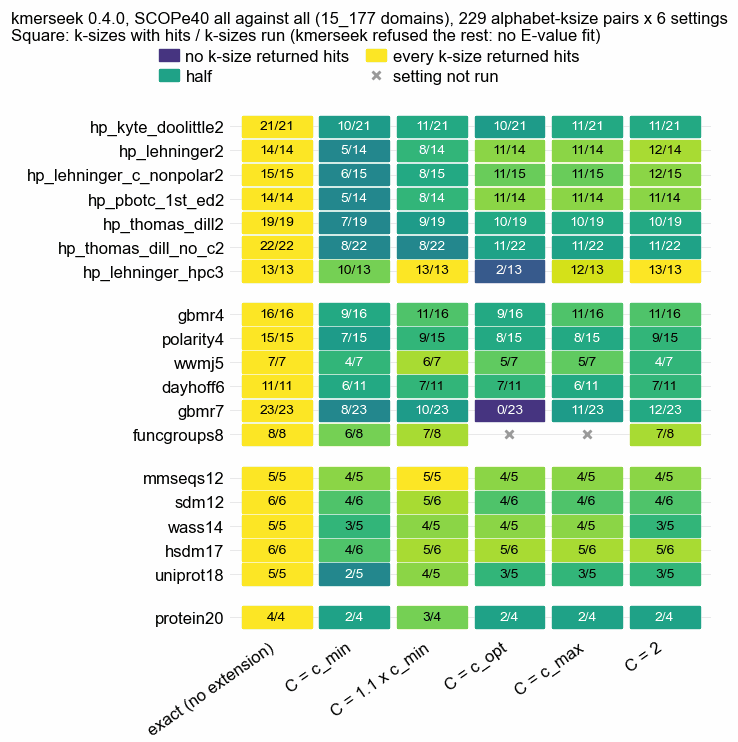

In [4]:
search = auc.group_by("alphabet", "ksize", "setting").agg(
    (pl.col("status") == "nofit").any().alias("nofit")
)
fit_share = (
    search.group_by("alphabet", "setting")
    .agg(pl.len().alias("n_ksizes"), (~pl.col("nofit")).sum().alias("n_fit"))
    .with_columns((pl.col("n_fit") / pl.col("n_ksizes")).alias("share_fit"))
)
wide = (
    fit_share.with_columns(
        (pl.col("n_fit").cast(str) + "/" + pl.col("n_ksizes").cast(str)).alias("fit")
    )
    .pivot(on="setting", index="alphabet", values="fit")
    .select(["alphabet"] + SETTINGS)
)
print("Searches with hits / searches run, per alphabet and setting")
print(
    wide.sort(
        pl.col("alphabet").replace_strict({a: i for i, a in enumerate(ALPHABETS)})
    )
)
print(
    search.group_by("setting")
    .agg(pl.len().alias("searches"), pl.col("nofit").sum().alias("nofit"))
    .sort("setting")
)

pos = alphabet_positions(ALPHABETS)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 95)
cmap = plt.get_cmap("viridis")
share = {(r["alphabet"], r["setting"]): r for r in fit_share.iter_rows(named=True)}
for j, s in enumerate(SETTINGS):
    for a, y in pos.items():
        r = share.get((a, s))
        if r is None:
            ax.plot(j, y, marker="x", color=pf.GREY, ms=3, label="setting not run")
            continue
        ax.add_patch(
            plt.Rectangle(
                (j - 0.45, y - 0.45), 0.9, 0.9, color=cmap(0.15 + 0.85 * r["share_fit"])
            )
        )
        ax.text(
            j,
            y,
            f"{r['n_fit']}/{r['n_ksizes']}",
            ha="center",
            va="center",
            fontsize=5,
            color="white" if r["share_fit"] < 0.6 else "black",
        )
ax.set_xlim(-0.6, len(SETTINGS) - 0.4)
ax.set_xticks(
    range(len(SETTINGS)), [SETTING_LABEL[s] for s in SETTINGS], rotation=35, ha="right"
)
alphabet_axis(ax, pos)
ax.spines[["left", "bottom"]].set_visible(False)
ax.tick_params(length=0)
handles = [
    plt.Rectangle((0, 0), 1, 1, color=cmap(0.15 + 0.85 * v)) for v in (0, 0.5, 1)
]
handles.append(plt.Line2D([], [], marker="x", ls="", color=pf.GREY, ms=3))
fig.legend(
    handles,
    [
        "no k-size returned hits",
        "half",
        "every k-size returned hits",
        "setting not run",
    ],
    loc="outside upper center",
    ncol=2,
    title="kmerseek 0.4.0, SCOPe40 all against all (15_177 domains), 229 alphabet-ksize pairs x 6 settings\n"
    "Square: k-sizes with hits / k-sizes run (kmerseek refused the rest: no E-value fit)",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_searches_with_hits", formats=("pdf", "png"))

## 2. Which score column ranks best

Every point is one search (one alphabet, k and setting). The x position is its family (left) or
superfamily (right) AUC when hits are ranked by that column. Columns are sorted by their median
over the extension searches (black bar). `exact` searches are drawn too, in black; three
columns exist only with extension.

A pair of hits with the same score can be ranked either way. The AUC here puts the false
positive first in every tie (the lower bound). The table also gives the median gap to the
other order, false positive last; where the gap is large, the column's AUC depends on how ties
fall rather than on the score.

Extension searches only (5 settings). AUC over FoldSeek's 5_713 queries, false positive first in ties.
shape: (42, 7)
┌─────────────┬─────────────────────────────┬────────────┬────────────┬─────────┬────────────────┬─────────────┐
│ level       ┆ score                       ┆ n_searches ┆ median_auc ┆ max_auc ┆ median_tie_gap ┆ max_tie_gap │
│ ---         ┆ ---                         ┆ ---        ┆ ---        ┆ ---     ┆ ---            ┆ ---         │
│ str         ┆ str                         ┆ u32        ┆ f64        ┆ f64     ┆ f64            ┆ f64         │
╞═════════════╪═════════════════════════════╪════════════╪════════════╪═════════╪════════════════╪═════════════╡
│ family      ┆ region_evalue               ┆ 659        ┆ 0.062      ┆ 0.295   ┆ 0.000          ┆ 0.159       │
│ family      ┆ region_ka_bits              ┆ 659        ┆ 0.060      ┆ 0.277   ┆ 0.000          ┆ 0.159       │
│ family      ┆ region_tfidf                ┆ 659        ┆ 0.055      ┆ 0.242   ┆ 0.000    

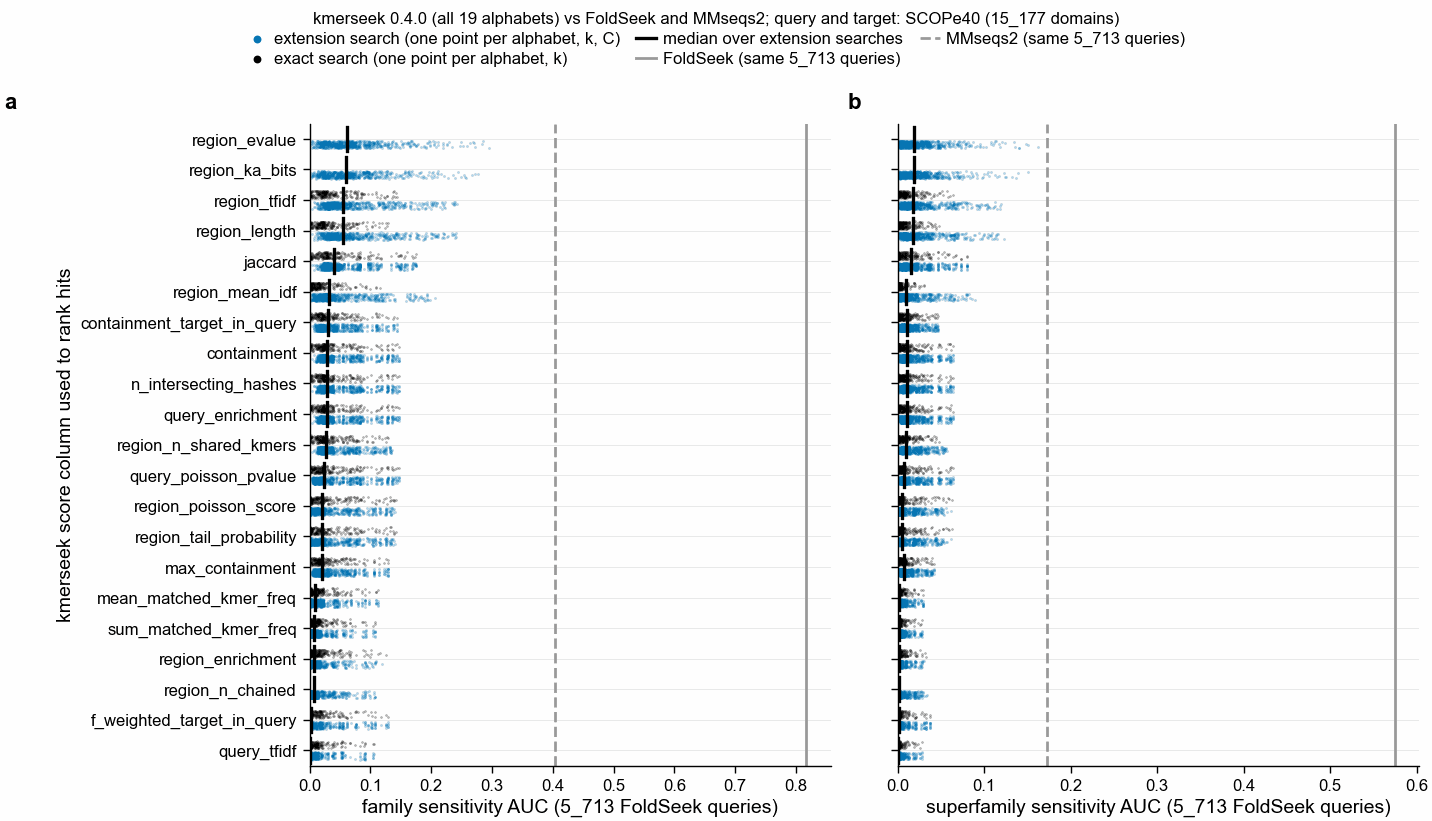

In [5]:
ok = auc.filter(pl.col("status") == "ok", pl.col("level").is_in(LEVELS)).with_columns(
    (pl.col("auc_ref_optimistic") - pl.col("auc_ref")).alias("tie_gap")
)
ext = ok.filter(pl.col("setting").is_in(EXTENSION_SETTINGS))
by_score = (
    ext.group_by("level", "score")
    .agg(
        pl.len().alias("n_searches"),
        pl.col("auc_ref").median().alias("median_auc"),
        pl.col("auc_ref").max().alias("max_auc"),
        pl.col("tie_gap").median().alias("median_tie_gap"),
        pl.col("tie_gap").max().alias("max_tie_gap"),
    )
    .sort("level", "median_auc", descending=[False, True])
)
print(
    "Extension searches only (5 settings). AUC over FoldSeek's 5_713 queries, false positive first in ties."
)
print(by_score)

order = by_score.filter(pl.col("level") == "family")["score"].to_list()
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 105, ncols=2, sharey=True)
rng = np.random.default_rng(0)
for ax, level in zip(axs, LEVELS):
    sub = ok.filter(pl.col("level") == level)
    for i, sc in enumerate(order):
        for s, lab, col in [
            (
                "extension",
                "extension search (one point per alphabet, k, C)",
                pf.OKABE_ITO["blue"],
            ),
            (
                "exact",
                "exact search (one point per alphabet, k)",
                pf.OKABE_ITO["black"],
            ),
        ]:
            m = (
                pl.col("setting").is_in(EXTENSION_SETTINGS)
                if s == "extension"
                else pl.col("setting") == "exact"
            )
            v = sub.filter(pl.col("score") == sc, m)["auc_ref"].to_numpy()
            dy = 0.18 if s == "extension" else -0.18
            ax.scatter(
                v,
                i + dy + rng.uniform(-0.12, 0.12, v.size),
                s=1,
                alpha=0.3,
                color=col,
                lw=0,
                label=lab,
            )
        med = by_score.filter(pl.col("level") == level, pl.col("score") == sc)[
            "median_auc"
        ].item()
        ax.plot(
            [med, med],
            [i - 0.4, i + 0.4],
            color="black",
            lw=1.2,
            label="median over extension searches",
        )
    for tool, st in TOOL_STYLE.items():
        ax.axvline(TOOL_AUC[(tool, level)], label=f"{tool} (same 5_713 queries)", **st)
    ax.set_yticks(range(len(order)), order)
    ax.set_ylim(len(order) - 0.5, -0.5)
    for i in range(len(order)):
        ax.axhline(i, color="0.9", lw=0.3, zorder=0)
    ax.set_xlabel(f"{level} sensitivity AUC (5_713 FoldSeek queries)")
    ax.set_xlim(0, None)
axs[0].set_ylabel("kmerseek score column used to rank hits")
pf.panel_label(axs[0], "a", dx_pt=-110)
pf.panel_label(axs[1], "b")
leg = pf.shared_legend(
    fig,
    ncol=3,
    title="kmerseek 0.4.0 (all 19 alphabets) vs FoldSeek and MMseqs2; "
    "query and target: SCOPe40 (15_177 domains)",
)
for h in leg.legend_handles:
    if hasattr(h, "set_alpha"):
        h.set_alpha(1)
    if hasattr(h, "set_sizes"):
        h.set_sizes([8])
pf.save(fig, FIG_DIR / f"{FIG_STEM}_auc_by_score_column", formats=("pdf", "png"))

## 3. Best alphabet, k and setting, against FoldSeek and MMseqs2

Hits ranked by `region_evalue` (section 2's choice). `exact` searches have no E-value, so they
are ranked by `jaccard`, the column with the highest median family AUC among `exact` searches.
Each small dot is one k and setting of that alphabet. The large dot is the alphabet's best,
labelled with its k and setting; a triangle on the label means that k is the lowest k run for
that alphabet (its k_min).

exact searches ranked by: jaccard
family: best per alphabet (FoldSeek 0.817, MMseqs2 0.403)
shape: (19, 10)
┌──────────────────────────┬───────┬───────┬───────┬─────────────────┬─────────┬───────────────┬─────────┬────────────────────┬─────────────────┐
│ alphabet                 ┆ ksize ┆ k_min ┆ k_max ┆ best_k_is_k_min ┆ setting ┆ score         ┆ auc_ref ┆ auc_ref_optimistic ┆ n_ref_with_hits │
│ ---                      ┆ ---   ┆ ---   ┆ ---   ┆ ---             ┆ ---     ┆ ---           ┆ ---     ┆ ---                ┆ ---             │
│ str                      ┆ i64   ┆ i64   ┆ i64   ┆ bool            ┆ str     ┆ str           ┆ f64     ┆ f64                ┆ i64             │
╞══════════════════════════╪═══════╪═══════╪═══════╪═════════════════╪═════════╪═══════════════╪═════════╪════════════════════╪═════════════════╡
│ mmseqs12                 ┆ 6     ┆ 6     ┆ 10    ┆ true            ┆ c_max   ┆ region_evalue ┆ 0.295   ┆ 0.295              ┆ 3136            │
│ sdm12         

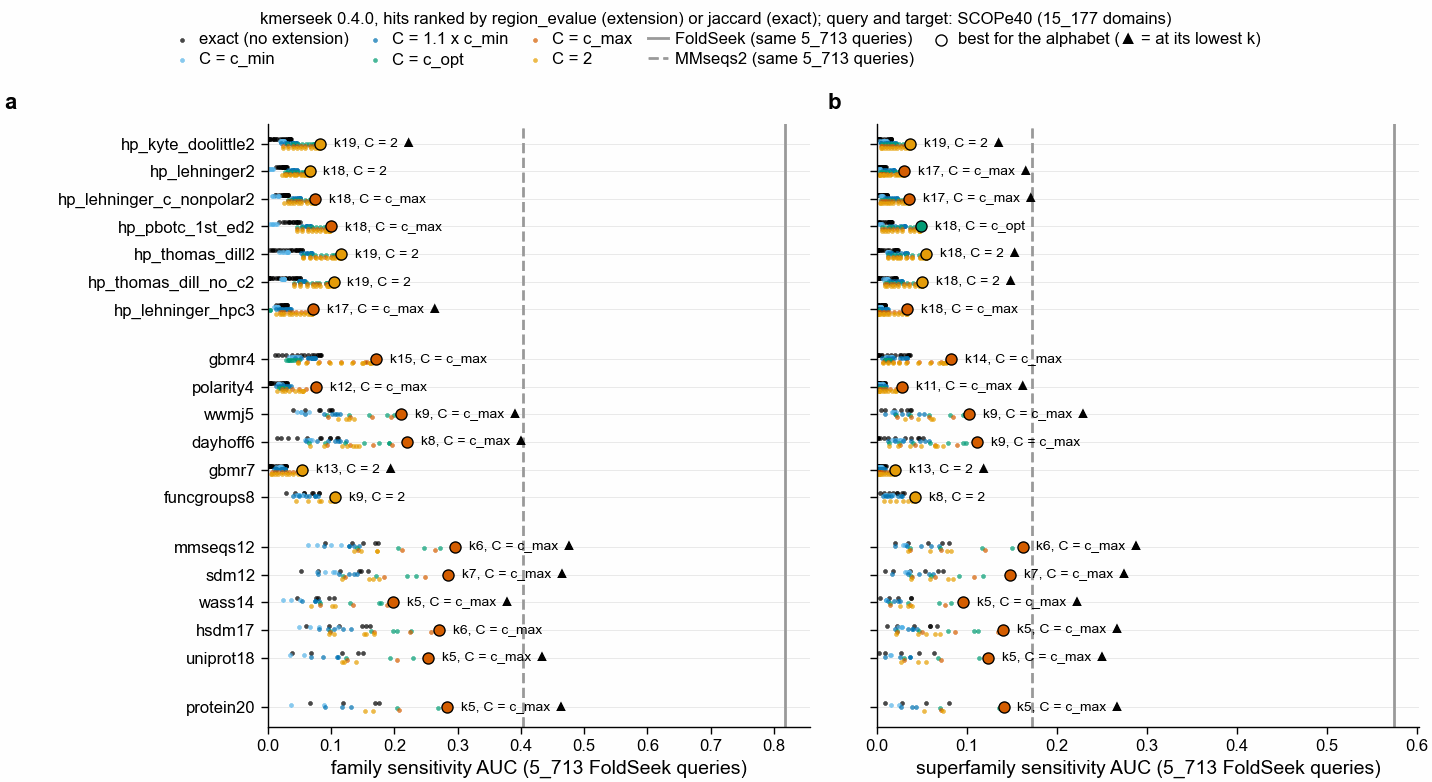

In [6]:
EXACT_SCORE = (
    ok.filter(pl.col("setting") == "exact", pl.col("level") == "family")
    .group_by("score")
    .agg(pl.col("auc_ref").median())
    .sort("auc_ref", descending=True)["score"][0]
)
print("exact searches ranked by:", EXACT_SCORE)
chosen = ok.filter(
    (pl.col("setting").is_in(EXTENSION_SETTINGS) & (pl.col("score") == "region_evalue"))
    | ((pl.col("setting") == "exact") & (pl.col("score") == EXACT_SCORE))
).join(ks, on="alphabet")
best = (
    chosen.sort("auc_ref", descending=True)
    .group_by("alphabet", "level", maintain_order=True)
    .head(1)
    .with_columns((pl.col("ksize") == pl.col("k_min")).alias("best_k_is_k_min"))
    .select(
        "level",
        "alphabet",
        "ksize",
        "k_min",
        "k_max",
        "best_k_is_k_min",
        "setting",
        "score",
        "auc_ref",
        "auc_ref_optimistic",
        "n_ref_with_hits",
    )
)
for level in LEVELS:
    print(
        f"{level}: best per alphabet (FoldSeek {TOOL_AUC[('FoldSeek', level)]:.3f}, "
        f"MMseqs2 {TOOL_AUC[('MMseqs2', level)]:.3f})"
    )
    print(
        best.filter(pl.col("level") == level)
        .sort("auc_ref", descending=True)
        .drop("level")
    )

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 100, ncols=2, sharey=True)
for ax, level in zip(axs, LEVELS):
    sub = chosen.filter(pl.col("level") == level)
    for s in SETTINGS:
        ss = sub.filter(pl.col("setting") == s)
        ax.scatter(
            ss["auc_ref"],
            [pos[a] + 0.15 * (SETTINGS.index(s) - 2.5) / 2.5 for a in ss["alphabet"]],
            s=3,
            color=SETTING_COLOUR[s],
            lw=0,
            alpha=0.7,
            label=SETTING_LABEL[s],
        )
    for r in best.filter(pl.col("level") == level).iter_rows(named=True):
        ax.scatter(
            r["auc_ref"],
            pos[r["alphabet"]],
            s=16,
            color=SETTING_COLOUR[r["setting"]],
            edgecolor="black",
            lw=0.5,
            zorder=3,
        )
        tag = " ▲" if r["best_k_is_k_min"] else ""
        ax.annotate(
            f"k{r['ksize']}, {SETTING_LABEL[r['setting']]}{tag}",
            (r["auc_ref"], pos[r["alphabet"]]),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=5,
        )
    for tool, st in TOOL_STYLE.items():
        ax.axvline(TOOL_AUC[(tool, level)], label=f"{tool} (same 5_713 queries)", **st)
    alphabet_axis(ax, pos)
    ax.set_xlim(0, TOOL_AUC[("FoldSeek", level)] * 1.05)
    ax.set_xlabel(f"{level} sensitivity AUC (5_713 FoldSeek queries)")
axs[0].scatter(
    [],
    [],
    s=16,
    color="white",
    edgecolor="black",
    lw=0.5,
    label="best for the alphabet (▲ = at its lowest k)",
)
pf.panel_label(axs[0], "a", dx_pt=-95)
pf.panel_label(axs[1], "b")
pf.shared_legend(
    fig,
    ncol=5,
    title="kmerseek 0.4.0, hits ranked by region_evalue (extension) or jaccard (exact); "
    "query and target: SCOPe40 (15_177 domains)",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_best_per_alphabet", formats=("pdf", "png"))

## 4. Sensitivity against k for the HP alphabets and protein20

The same ranking as section 3, family level, every k run. x is k (numeric), one line per
setting. A grey cross on the x axis marks a k where kmerseek refused that setting (no E-value
fit). Under each HP alphabet's name are its residue classes as kmerseek defines them: H
(hydrophobic), P (polar), and for `hp_lehninger_hpc3` a third class, C, for cysteine alone.

{'hp_kyte_doolittle2': {'H': 'ACFILMV', 'P': 'DEGHKNPQRSTWY'}, 'hp_lehninger2': {'H': 'AFGILMPVWY', 'P': 'CDEHKNQRST'}, 'hp_lehninger_c_nonpolar2': {'H': 'ACFGILMPVWY', 'P': 'DEHKNQRST'}, 'hp_pbotc_1st_ed2': {'H': 'ACFILMPVWY', 'P': 'DEGHKNQRST'}, 'hp_thomas_dill2': {'H': 'ACFILMVWY', 'P': 'DEGHKNPQRST'}, 'hp_thomas_dill_no_c2': {'H': 'AFILMVWY', 'P': 'CDEGHKNPQRST'}, 'hp_lehninger_hpc3': {'H': 'AFGILMPVWY', 'P': 'DEHKNQRST', 'C': 'C'}}
Family AUC by k (columns: setting), HP alphabets and protein20
hp_kyte_doolittle2
shape: (21, 7)
┌───────┬───────┬───────┬────────────┬───────┬───────┬───────┐
│ ksize ┆ exact ┆ c_min ┆ c_min_x1.1 ┆ c_opt ┆ c_max ┆ c2    │
│ ---   ┆ ---   ┆ ---   ┆ ---        ┆ ---   ┆ ---   ┆ ---   │
│ i64   ┆ f64   ┆ f64   ┆ f64        ┆ f64   ┆ f64   ┆ f64   │
╞═══════╪═══════╪═══════╪════════════╪═══════╪═══════╪═══════╡
│ 19    ┆ 0.024 ┆ 0.019 ┆ 0.040      ┆ 0.073 ┆ 0.078 ┆ 0.082 │
│ 20    ┆ 0.028 ┆ 0.023 ┆ 0.044      ┆ 0.073 ┆ 0.077 ┆ 0.081 │
│ 21    ┆ 0.031 ┆ 0.0

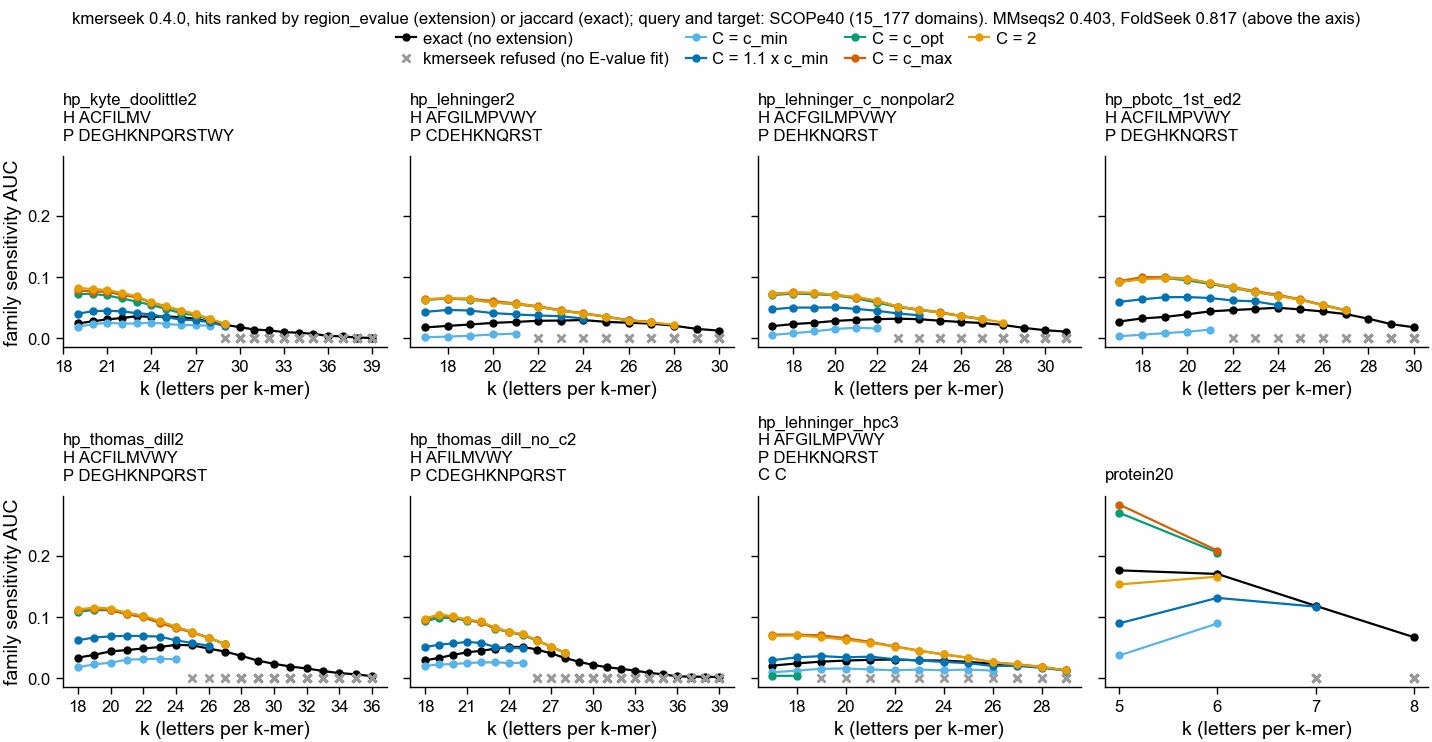

In [7]:
import ortholog_analysis_utils as ou

PANELS = [a for a in ALPHABETS if a.startswith("hp_")] + ["protein20"]
# Residue classes as kmerseek defines them (src/rust/alphabets.rs, kmerseek d79f863);
# ortholog_analysis_utils holds the two-class ones under names without the trailing 2.
OU_NAME = {"hp_lehninger_c_nonpolar2": "hp_lehninger_plus_c"}
HP_CLASSES = {}
for a in PANELS[:-1]:
    g = ou.ALPHABET_AA_GROUPS.get(OU_NAME.get(a, re.sub(r"2$", "", a)))
    if g:
        HP_CLASSES[a] = {k.upper(): v for k, v in g.items()}
HP_CLASSES["hp_lehninger_hpc3"] = {"H": "AFGILMPVWY", "P": "DEHKNQRST", "C": "C"}
print(HP_CLASSES)
nofit = (
    auc.filter(pl.col("status") == "nofit")
    .select("alphabet", "ksize", "setting")
    .unique()
)
fam = chosen.filter(pl.col("level") == "family")
print("Family AUC by k (columns: setting), HP alphabets and protein20")
for a in PANELS:
    print(a)
    print(
        fam.filter(pl.col("alphabet") == a)
        .pivot(on="setting", index="ksize", values="auc_ref")
        .sort("ksize")
        .select(
            ["ksize"]
            + [
                s
                for s in SETTINGS
                if s in fam.filter(pl.col("alphabet") == a)["setting"].unique()
            ]
        )
    )

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, nrows=2, ncols=4, sharey=True)
for ax, a in zip(axs.flat, PANELS):
    sub = fam.filter(pl.col("alphabet") == a)
    for s in SETTINGS:
        ss = sub.filter(pl.col("setting") == s).sort("ksize")
        ax.plot(
            ss["ksize"],
            ss["auc_ref"],
            marker="o",
            ms=2,
            lw=0.8,
            color=SETTING_COLOUR[s],
            label=SETTING_LABEL[s],
        )
        nf = nofit.filter(pl.col("alphabet") == a, pl.col("setting") == s)["ksize"]
        ax.plot(
            nf,
            np.zeros(len(nf)),
            ls="",
            marker="x",
            ms=3,
            color=pf.GREY,
            label="kmerseek refused (no E-value fit)",
        )
    classes = HP_CLASSES.get(a, {})
    ax.set_title(
        "\n".join([a] + [f"{c} {aas}" for c, aas in classes.items()]),
        fontsize=6,
        loc="left",
    )
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_xlabel("k (letters per k-mer)")
axs[0, 0].set_ylabel("family sensitivity AUC")
axs[1, 0].set_ylabel("family sensitivity AUC")
pf.shared_legend(
    fig,
    ncol=4,
    title="kmerseek 0.4.0, hits ranked by region_evalue (extension) or jaccard (exact); "
    "query and target: SCOPe40 (15_177 domains). "
    f"MMseqs2 {TOOL_AUC[('MMseqs2', 'family')]:.3f}, FoldSeek {TOOL_AUC[('FoldSeek', 'family')]:.3f} (above the axis)",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_hp_protein20_auc_vs_k", formats=("pdf", "png"))

## 5. Does extension beat exact matching?

One point per alphabet-ksize pair and extension setting: x is the family AUC of the `exact`
search (ranked by `jaccard`), y the same pair's AUC with extension (ranked by `region_evalue`).
Above the grey diagonal, extension found more true positives before the first false positive.

Family AUC, extension vs exact, per alphabet-ksize pair where the extension search returned hits
shape: (5, 5)
┌────────────┬─────────┬────────────────────┬──────────────┬──────────────────┐
│ setting    ┆ n_pairs ┆ n_extension_better ┆ median_exact ┆ median_extension │
│ ---        ┆ ---     ┆ ---                ┆ ---          ┆ ---              │
│ str        ┆ i64     ┆ i64                ┆ f64          ┆ f64              │
╞════════════╪═════════╪════════════════════╪══════════════╪══════════════════╡
│ c_min      ┆ 110     ┆ 0                  ┆ 0.041        ┆ 0.025            │
│ c_min_x1.1 ┆ 141     ┆ 71                 ┆ 0.044        ┆ 0.055            │
│ c_opt      ┆ 117     ┆ 99                 ┆ 0.044        ┆ 0.072            │
│ c_max      ┆ 140     ┆ 140                ┆ 0.036        ┆ 0.074            │
│ c2         ┆ 151     ┆ 142                ┆ 0.036        ┆ 0.070            │
└────────────┴─────────┴────────────────────┴──────────────┴──────────────────┘


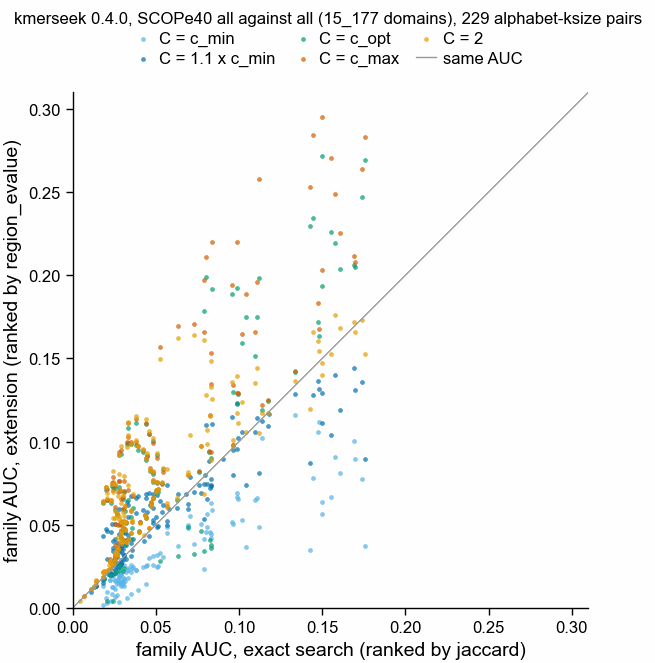

In [8]:
fam_w = fam.pivot(on="setting", index=["alphabet", "ksize"], values="auc_ref")
rows = []
for s in EXTENSION_SETTINGS:
    sub = fam_w.select(
        "alphabet", "ksize", "exact", pl.col(s).alias("ext")
    ).drop_nulls()
    rows.append(
        {
            "setting": s,
            "n_pairs": sub.height,
            "n_extension_better": int((sub["ext"] > sub["exact"]).sum()),
            "median_exact": sub["exact"].median(),
            "median_extension": sub["ext"].median(),
        }
    )
vs_exact = pl.DataFrame(rows)
print(
    "Family AUC, extension vs exact, per alphabet-ksize pair where the extension search returned hits"
)
print(vs_exact)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 85)
for s in EXTENSION_SETTINGS:
    sub = fam_w.select("exact", s).drop_nulls()
    ax.scatter(
        sub["exact"],
        sub[s],
        s=3,
        lw=0,
        alpha=0.7,
        color=SETTING_COLOUR[s],
        label=SETTING_LABEL[s],
    )
lim = max(fam_w.select(pl.exclude("alphabet", "ksize")).max().row(0)) * 1.05
ax.plot([0, lim], [0, lim], color=pf.GREY, lw=0.5, label="same AUC")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.set_xlabel("family AUC, exact search (ranked by jaccard)")
ax.set_ylabel("family AUC, extension (ranked by region_evalue)")
fig.legend(
    loc="outside upper center",
    ncol=3,
    title="kmerseek 0.4.0, SCOPe40 all against all (15_177 domains), 229 alphabet-ksize pairs",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_extension_vs_exact", formats=("pdf", "png"))

## 6. Below k_min: the follow-up run

Section 3 left one question open: for 10 of 19 alphabets the best k was the lowest k run, so
sensitivity might keep rising at smaller k. A second run on Sherlock (step 1 of the
[PR 107](https://github.com/seanome/2024-kmerseek-analysis/pull/107) follow-up, head job
47546661, 2026-10-12, same image and settings) searched k_min − 1 and k_min − 2 for the 16
alphabets whose best family or superfamily AUC sat at k_min, never under 15 bits per k-mer
(k × log2 classes). That is 27 alphabet-ksize pairs and 162 searches; all 162 scored.
funcgroups8, gbmr4 and hp_pbotc_1st_ed2 were left out: their best k was above k_min.

The rule was set before this run: if the best AUC below k_min beats the best at k_min to k_max
for most alphabets, the sweep's k range moves down; otherwise k_min stands as the lower end and
section 3's best k-sizes are final.

The figure puts both runs on one row per alphabet: a circle at the best AUC of the first sweep
(k_min to k_max), a triangle at the best AUC below k_min, each labelled with its k. A triangle to
the left of its circle means the smaller k-sizes did worse. Hits are ranked as in section 3.

/Users/olga/data/scope/results-scope40-alphabet-ksize-v040-below-kmin/scope40_v040_auc.tsv
sha256 de5aa346313e36a30e50850c67b466b91bb418398a02676d3e0c9061299e3ea6
shape: (3, 2)
┌──────────┬──────┐
│ status   ┆ len  │
│ ---      ┆ ---  │
│ str      ┆ u32  │
╞══════════╪══════╡
│ constant ┆ 81   │
│ nofit    ┆ 2    │
│ ok       ┆ 9837 │
└──────────┴──────┘
How many alphabets do better below k_min
shape: (3, 5)
┌─────────────┬─────────────────────┬─────────────┬────────────────┬───────────────┐
│ level       ┆ n_better_below_kmin ┆ n_alphabets ┆ largest_change ┆ median_change │
│ ---         ┆ ---                 ┆ ---         ┆ ---            ┆ ---           │
│ str         ┆ u32                 ┆ u32         ┆ f64            ┆ f64           │
╞═════════════╪═════════════════════╪═════════════╪════════════════╪═══════════════╡
│ family      ┆ 0                   ┆ 16          ┆ -0.001         ┆ -0.015        │
│ fold        ┆ 1                   ┆ 16          ┆ 0.000          ┆ -0.002   

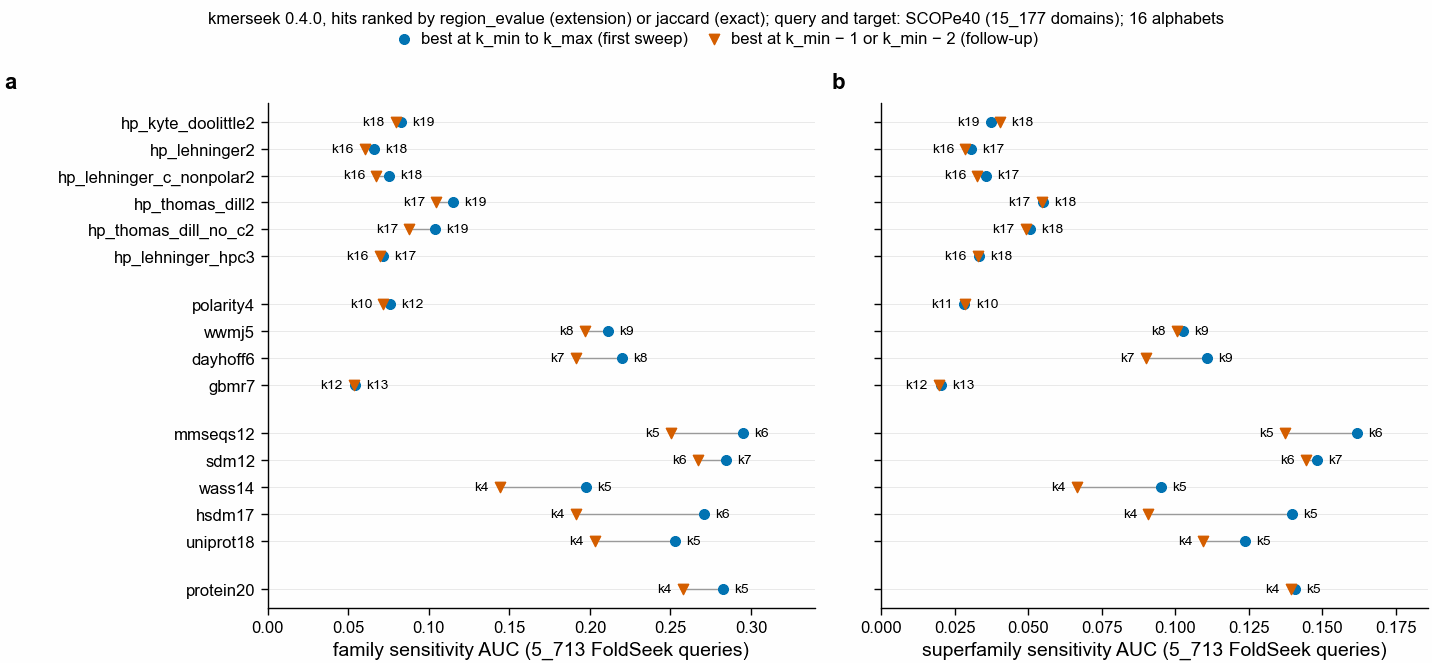

In [9]:
BELOW_TSV = Path(
    os.environ.get(
        "NB277_BELOW_TSV",
        Path.home()
        / "data/scope/results-scope40-alphabet-ksize-v040-below-kmin/scope40_v040_auc.tsv",
    )
)
print(BELOW_TSV)
print("sha256", hashlib.sha256(BELOW_TSV.read_bytes()).hexdigest())
below_auc = pl.read_csv(BELOW_TSV, separator="\t")
print(below_auc.group_by("status").len().sort("status"))


def best_per_alphabet(d, tag):
    "Best AUC per alphabet and level, hits ranked by region_evalue (extension) or jaccard (exact)."
    d = d.filter(pl.col("status") == "ok").filter(
        (
            pl.col("setting").is_in(EXTENSION_SETTINGS)
            & (pl.col("score") == "region_evalue")
        )
        | ((pl.col("setting") == "exact") & (pl.col("score") == EXACT_SCORE))
    )
    return (
        d.sort("auc_ref", descending=True)
        .group_by("alphabet", "level")
        .head(1)
        .select(
            "alphabet",
            "level",
            pl.col("ksize").alias(f"k_{tag}"),
            pl.col("setting").alias(f"setting_{tag}"),
            pl.col("auc_ref").alias(f"auc_{tag}"),
        )
    )


compare = (
    best_per_alphabet(below_auc, "below")
    .join(best_per_alphabet(auc, "first"), on=["alphabet", "level"])
    .join(ks.select("alphabet", "k_min"), on="alphabet")
    .filter(pl.col("level").is_in(["family", "superfamily", "fold"]))
    .with_columns((pl.col("auc_below") - pl.col("auc_first")).alias("change"))
    .sort("level", "alphabet")
)
print("How many alphabets do better below k_min")
print(
    compare.group_by("level")
    .agg(
        (pl.col("change") > 0).sum().alias("n_better_below_kmin"),
        pl.len().alias("n_alphabets"),
        pl.col("change").max().alias("largest_change"),
        pl.col("change").median().alias("median_change"),
    )
    .sort("level")
)
print("Best AUC per alphabet, first sweep (k_min to k_max) and below k_min")
print(
    compare.filter(pl.col("level") != "fold").sort(
        "level", "auc_first", descending=[False, True]
    )
)

BELOW_COLOUR = {"first": pf.OKABE_ITO["blue"], "below": pf.OKABE_ITO["vermillion"]}
below_alphabets = [a for a in ALPHABETS if a in set(compare["alphabet"])]
bpos = alphabet_positions(below_alphabets)
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 85, ncols=2, sharey=True)
for ax, level in zip(axs, LEVELS):
    sub = compare.filter(pl.col("level") == level)
    for r in sub.iter_rows(named=True):
        y = bpos[r["alphabet"]]
        ax.plot(
            [r["auc_below"], r["auc_first"]], [y, y], color=pf.GREY, lw=0.5, zorder=1
        )
        left_first = r["auc_first"] < r["auc_below"]
        ax.annotate(
            f"k{r['k_first']}",
            (r["auc_first"], y),
            xytext=(-4 if left_first else 4, 0),
            textcoords="offset points",
            va="center",
            ha="right" if left_first else "left",
            fontsize=5,
        )
        ax.annotate(
            f"k{r['k_below']}",
            (r["auc_below"], y),
            xytext=(4 if left_first else -4, 0),
            textcoords="offset points",
            va="center",
            ha="left" if left_first else "right",
            fontsize=5,
        )
    ax.scatter(
        sub["auc_first"],
        [bpos[a] for a in sub["alphabet"]],
        s=12,
        marker="o",
        color=BELOW_COLOUR["first"],
        zorder=2,
        label="best at k_min to k_max (first sweep)",
    )
    ax.scatter(
        sub["auc_below"],
        [bpos[a] for a in sub["alphabet"]],
        s=14,
        marker="v",
        color=BELOW_COLOUR["below"],
        zorder=3,
        label="best at k_min − 1 or k_min − 2 (follow-up)",
    )
    alphabet_axis(ax, bpos)
    ax.set_xlim(
        0, sub.select(pl.max_horizontal("auc_first", "auc_below")).max().item() * 1.15
    )
    ax.set_xlabel(f"{level} sensitivity AUC (5_713 FoldSeek queries)")
pf.panel_label(axs[0], "a", dx_pt=-95)
pf.panel_label(axs[1], "b")
pf.shared_legend(
    fig,
    ncol=2,
    title="kmerseek 0.4.0, hits ranked by region_evalue (extension) or jaccard (exact); "
    "query and target: SCOPe40 (15_177 domains); 16 alphabets",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_below_kmin", formats=("pdf", "png"))

## 7. Same scale as FoldSeek and MMseqs2, fold and class levels, and identity bands

**Data.** Step 2 of the [PR 107](https://github.com/seanome/2024-kmerseek-analysis/pull/107)
follow-up (head job 47604583, 2026-10-12, same image): each alphabet's best family and
superfamily k from section 3, and every HP alphabet at k_min to k_min + 2, with `exact`,
`c_opt`, `c_max` and C = 2. 148 searches, all scored. Query set and target database are the
15_177 SCOPe40 domains, as before.

**Why the scale changes.** Sections 2-6 divide each query's count by the true positives
kmerseek *reported* for that query. FoldSeek's and MMseqs2's `.rocx` files divide by every
true positive in the database: for all 5_713 queries, sensitivity × (family size − 1) is a
whole number. A query where kmerseek reports 2 of its 24 family members, both above the
first false positive, scores 1.0 on the first scale and 2/24 on the second. Only the second
compares with the two tools. This section uses it (`auc_ref_db`).

**Two more levels.** Fold: true positive = same fold, different superfamily (as in section
3). Class: true positive = same SCOP class, different fold; false positive = a different
class. Neither tool's file has a class level.

**Identity bands.** Notebook 230's USalign pairs of SCOPe40 domains, each scored in both
directions, split by the share of identical residues over the structure-aligned columns. A
pair counts when kmerseek ranks it above the query's first false positive: the first
different-fold hit, or for class pairs the first different-class hit. A tie counts against
kmerseek.

Decision: if any HP alphabet beats protein20 and the 12-letter alphabets in the under-20%
band at some level, that level is where SCOPe40 can support the HP case; otherwise SCOPe40
stays a protein20 result (section 3).

/Users/olga/data/scope/results-scope40-alphabet-ksize-v040-best-k-identity/scope40_v040_auc.tsv sha256 bbe4883c4b14d56efd9f0e9998be5d1ea1b8ff8ad91ba64fa547eecd8bd98475
/Users/olga/data/scope/results-scope40-alphabet-ksize-v040-best-k-identity/scope40_v040_identity_bands.tsv sha256 e5b2f81fed537bff806319f07758352dda185cae3e72e897fd573616d29e1ae6
shape: (3, 2)
┌──────────┬───────┐
│ status   ┆ len   │
│ ---      ┆ ---   │
│ str      ┆ u32   │
╞══════════╪═══════╡
│ constant ┆ 114   │
│ nofit    ┆ 2     │
│ ok       ┆ 11808 │
└──────────┴───────┘
Best AUC per alphabet on FoldSeek's scale (auc_ref_db) and on the reported-hits scale (auc_ref)
shape: (19, 5)
┌──────────────────────────┬─────────┬─────────────┬─────────┬─────────┐
│ alphabet                 ┆ family  ┆ superfamily ┆ fold    ┆ class   │
│ ---                      ┆ ---     ┆ ---         ┆ ---     ┆ ---     │
│ str                      ┆ f64     ┆ f64         ┆ f64     ┆ f64     │
╞══════════════════════════╪═════════╪═════════

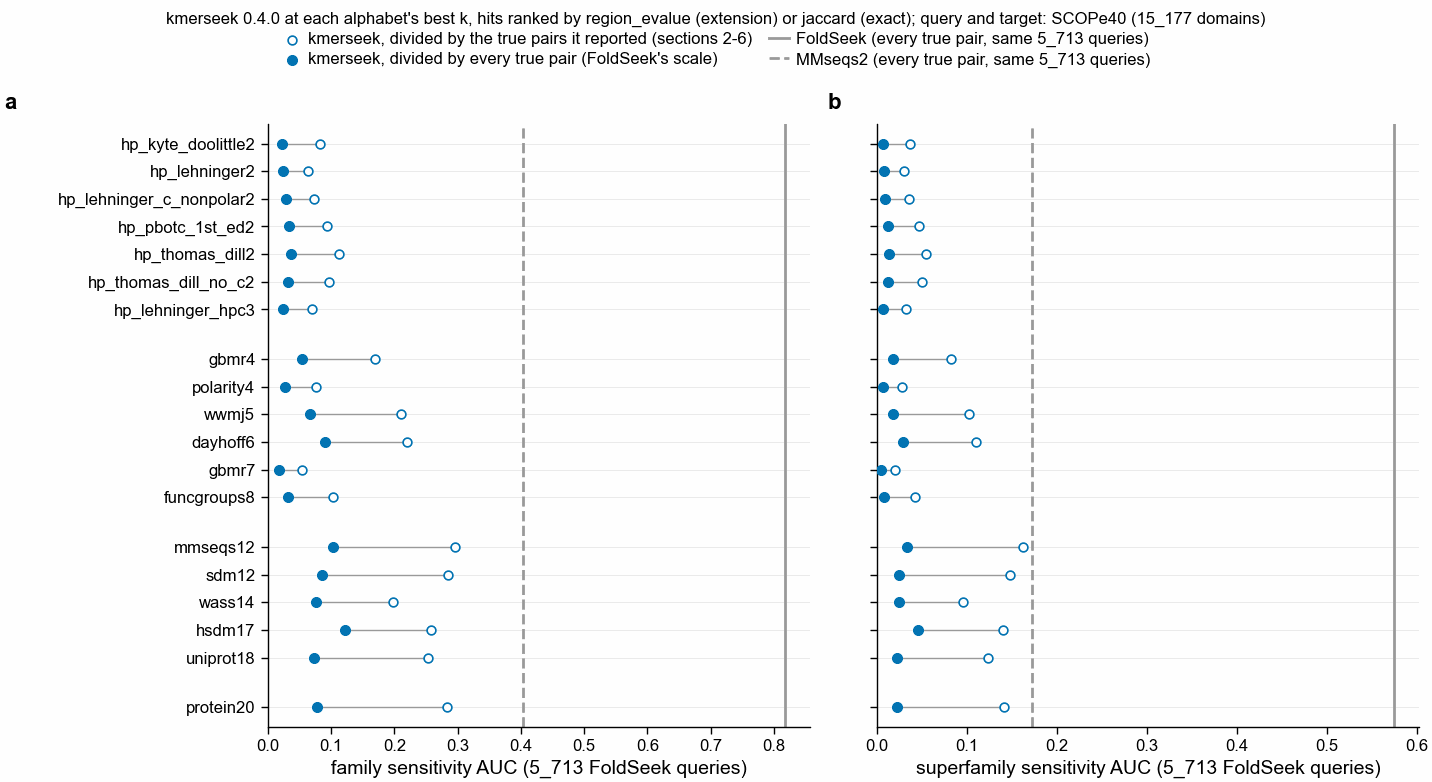

In [10]:
STEP2_DIR = Path(
    os.environ.get(
        "NB277_STEP2_DIR",
        Path.home() / "data/scope/results-scope40-alphabet-ksize-v040-best-k-identity",
    )
)
step2 = {}
for name in ("scope40_v040_auc.tsv", "scope40_v040_identity_bands.tsv"):
    path = STEP2_DIR / name
    print(path, "sha256", hashlib.sha256(path.read_bytes()).hexdigest())
    step2[name] = pl.read_csv(path, separator="\t", infer_schema_length=None)
s2 = step2["scope40_v040_auc.tsv"]
print(s2.group_by("status").len().sort("status"))
ALL_LEVELS = ["family", "superfamily", "fold", "class"]
ranked2 = s2.filter(pl.col("status") == "ok").filter(
    (pl.col("setting").is_in(EXTENSION_SETTINGS) & (pl.col("score") == "region_evalue"))
    | ((pl.col("setting") == "exact") & (pl.col("score") == EXACT_SCORE))
)
best_db = (
    ranked2.sort("auc_ref_db", descending=True)
    .group_by("alphabet", "level")
    .head(1)
    .select("alphabet", "level", "ksize", "setting", "auc_ref_db", "auc_ref")
)
print(
    "Best AUC per alphabet on FoldSeek's scale (auc_ref_db) and on the reported-hits scale (auc_ref)"
)
with pl.Config(float_precision=5):
    print(
        best_db.pivot(on="level", index="alphabet", values="auc_ref_db")
        .select(["alphabet"] + ALL_LEVELS)
        .sort("family", descending=True)
    )
for level in ["family", "superfamily", "fold"]:
    top = (
        best_db.filter(pl.col("level") == level)
        .sort("auc_ref_db", descending=True)
        .row(0, named=True)
    )
    print(
        f"{level}: best kmerseek {top['alphabet']} k{top['ksize']} {top['setting']} {top['auc_ref_db']:.4f} "
        f"(reported-hits scale {top['auc_ref']:.4f}); MMseqs2 {TOOL_AUC[('MMseqs2', level)]:.4f}, "
        f"FoldSeek {TOOL_AUC[('FoldSeek', level)]:.4f}"
    )

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 100, ncols=2, sharey=True)
for ax, level in zip(axs, LEVELS):
    sub = best_db.filter(pl.col("level") == level)
    ax.scatter(
        sub["auc_ref"],
        [pos[a] for a in sub["alphabet"]],
        s=10,
        marker="o",
        facecolor="white",
        edgecolor=pf.OKABE_ITO["blue"],
        lw=0.6,
        zorder=2,
        label="kmerseek, divided by the true pairs it reported (sections 2-6)",
    )
    ax.scatter(
        sub["auc_ref_db"],
        [pos[a] for a in sub["alphabet"]],
        s=12,
        marker="o",
        color=pf.OKABE_ITO["blue"],
        zorder=3,
        label="kmerseek, divided by every true pair (FoldSeek's scale)",
    )
    for r in sub.iter_rows(named=True):
        ax.plot(
            [r["auc_ref_db"], r["auc_ref"]],
            [pos[r["alphabet"]]] * 2,
            color=pf.GREY,
            lw=0.5,
            zorder=1,
        )
    for tool, st in TOOL_STYLE.items():
        ax.axvline(
            TOOL_AUC[(tool, level)],
            label=f"{tool} (every true pair, same 5_713 queries)",
            **st,
        )
    alphabet_axis(ax, pos)
    ax.set_xlim(0, TOOL_AUC[("FoldSeek", level)] * 1.05)
    ax.set_xlabel(f"{level} sensitivity AUC (5_713 FoldSeek queries)")
pf.panel_label(axs[0], "a", dx_pt=-95)
pf.panel_label(axs[1], "b")
pf.shared_legend(
    fig,
    ncol=2,
    title="kmerseek 0.4.0 at each alphabet's best k, hits ranked by region_evalue (extension) "
    "or jaccard (exact); query and target: SCOPe40 (15_177 domains)",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_same_scale_as_foldseek", formats=("pdf", "png"))

The next figure shows, for pairs under 20% identity, the share each alphabet ranks above the
query's first false positive, at its best k and setting for that pair class. One panel per
pair class; the x axis of each panel is fitted to its own values. The table under it gives the
counts behind each share, and the same share at every identity band.

Under 20% identity: pairs, reported, ranked above the first false positive (best k and setting per alphabet)
shape: (76, 8)
┌──────────────────────────────┬──────────────────────────┬───────┬─────────┬─────────┬────────────┬──────────────────┬──────────────────────┐
│ category                     ┆ alphabet                 ┆ ksize ┆ setting ┆ n_pairs ┆ n_reported ┆ n_above_first_fp ┆ share_above_first_fp │
│ ---                          ┆ ---                      ┆ ---   ┆ ---     ┆ ---     ┆ ---        ┆ ---              ┆ ---                  │
│ str                          ┆ str                      ┆ i64   ┆ str     ┆ i64     ┆ i64        ┆ i64              ┆ f64                  │
╞══════════════════════════════╪══════════════════════════╪═══════╪═════════╪═════════╪════════════╪══════════════════╪══════════════════════╡
│ diff_fold_same_class         ┆ polarity4                ┆ 11    ┆ exact   ┆ 15946   ┆ 988        ┆ 83               ┆ 0.00521              │
│ diff_fold_same_c

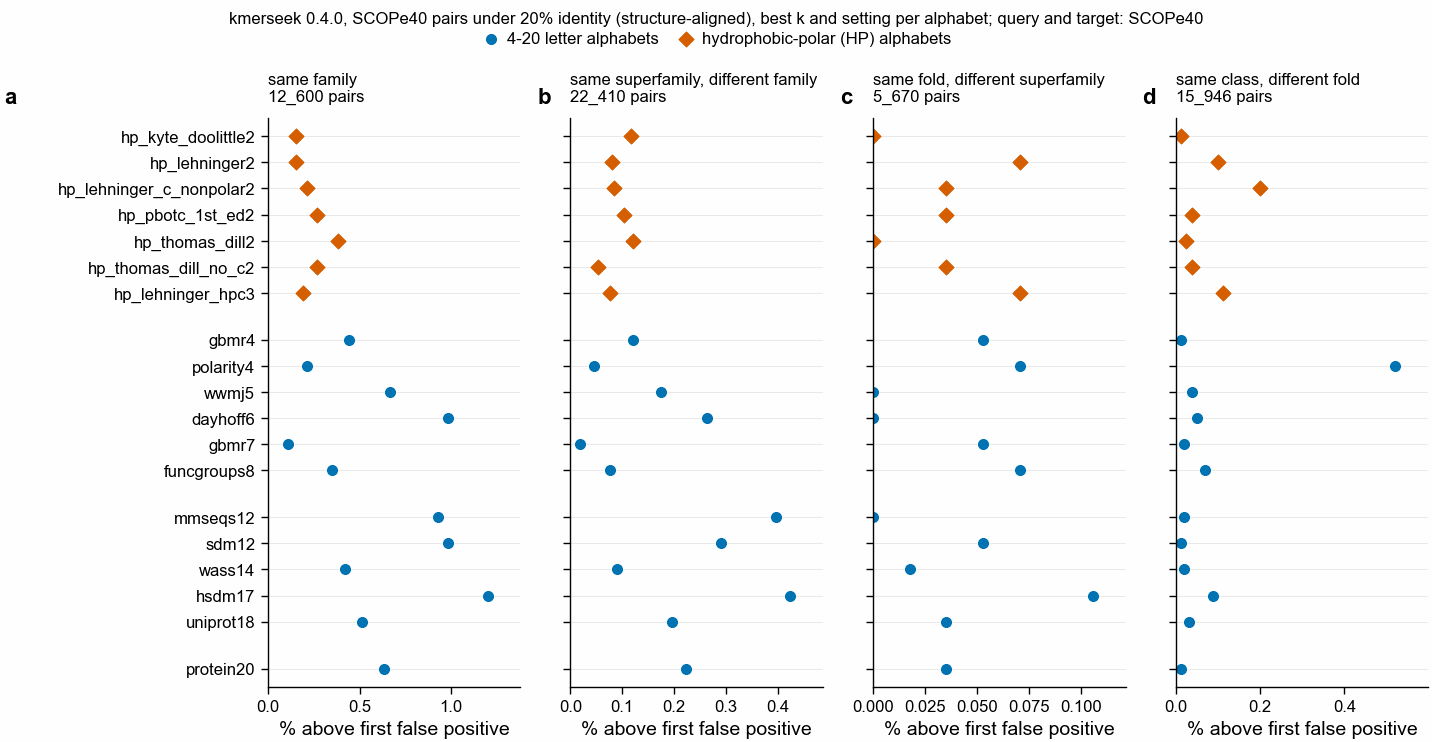

In [11]:
bands2 = (
    step2["scope40_v040_identity_bands.tsv"]
    .filter(pl.col("status") == "ok")
    .filter(
        (
            pl.col("setting").is_in(EXTENSION_SETTINGS)
            & (pl.col("score") == "region_evalue")
        )
        | ((pl.col("setting") == "exact") & (pl.col("score") == EXACT_SCORE))
    )
    .with_columns(
        (pl.col("n_above_first_fp") / pl.col("n_pairs")).alias("share_above_first_fp")
    )
)
best_band = (
    bands2.sort("share_above_first_fp", descending=True)
    .group_by("alphabet", "category", "identity_band")
    .head(1)
)
CATEGORY_LABEL = {
    "same_family": "same family",
    "same_superfamily_diff_family": "same superfamily, different family",
    "same_fold_diff_superfamily": "same fold, different superfamily",
    "diff_fold_same_class": "same class, different fold",
}
under20 = best_band.filter(pl.col("identity_band") == "0-20%")
print(
    "Under 20% identity: pairs, reported, ranked above the first false positive (best k and setting per alphabet)"
)
with pl.Config(float_precision=5):
    print(
        under20.select(
            "category",
            "alphabet",
            "ksize",
            "setting",
            "n_pairs",
            "n_reported",
            "n_above_first_fp",
            "share_above_first_fp",
        ).sort("category", "share_above_first_fp", descending=[False, True])
    )
print("Best share over all alphabets, by pair class and identity band")
print(
    best_band.group_by("category", "identity_band")
    .agg(pl.col("share_above_first_fp").max(), pl.col("n_pairs").first())
    .sort("category", "identity_band")
)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=4, sharey=True)
for ax, cat in zip(axs, CATEGORY_LABEL):
    sub = under20.filter(pl.col("category") == cat)
    hp = sub["alphabet"].str.starts_with("hp_")
    ax.scatter(
        sub.filter(~hp)["share_above_first_fp"] * 100,
        [pos[a] for a in sub.filter(~hp)["alphabet"]],
        s=12,
        color=pf.OKABE_ITO["blue"],
        label="4-20 letter alphabets",
    )
    ax.scatter(
        sub.filter(hp)["share_above_first_fp"] * 100,
        [pos[a] for a in sub.filter(hp)["alphabet"]],
        s=14,
        marker="D",
        color=pf.OKABE_ITO["vermillion"],
        label="hydrophobic-polar (HP) alphabets",
    )
    alphabet_axis(ax, pos)
    ax.set_xlim(0, sub["share_above_first_fp"].max() * 100 * 1.15)
    n = sub["n_pairs"][0]
    ax.set_title(f"{CATEGORY_LABEL[cat]}\n{n:_} pairs", fontsize=6, loc="left")
    ax.set_xlabel("% above first false positive")
for ax, letter in zip(axs, "abcd"):
    pf.panel_label(ax, letter, dx_pt=-95 if letter == "a" else -12)
pf.shared_legend(
    fig,
    ncol=2,
    title="kmerseek 0.4.0, SCOPe40 pairs under 20% identity (structure-aligned), "
    "best k and setting per alphabet; query and target: SCOPe40",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_identity_under_20", formats=("pdf", "png"))

## 8. Answers to the four decisions

The numbers each decision rests on, from the tables and figures of sections 1-7.

In [12]:
fam_best = best.filter(pl.col("level") == "family")
top_col = by_score.filter(pl.col("level") == "family").row(0, named=True)
print(
    f"1. Score column: {top_col['score']}, median family AUC {top_col['median_auc']:.3f} over "
    f"{top_col['n_searches']} extension searches; median tie gap {top_col['median_tie_gap']:.3f}, "
    f"largest {top_col['max_tie_gap']:.3f}"
)
for s_, g in fam_best.group_by("setting"):
    print(
        f"2. Best family AUC with {s_[0]} for {g.height} of {fam_best.height} alphabets: {', '.join(g['alphabet'])}"
    )
n_kmin = int(fam_best["best_k_is_k_min"].sum())
near = fam_best.filter(pl.col("ksize") <= pl.col("k_min") + 1).height
print(
    f"3. Best k is the alphabet's k_min for {n_kmin} of {fam_best.height} alphabets; "
    f"k_min or k_min + 1 for {near} of {fam_best.height}"
)
for lv, g in compare.group_by("level", maintain_order=True):
    print(
        f"3. Below k_min ({lv[0]}): better for {int((g['change'] > 0).sum())} of {g.height} alphabets, "
        f"largest change {g['change'].max():+.4f}"
    )
hp_best = (
    fam_best.filter(pl.col("alphabet").str.starts_with("hp_"))
    .sort("auc_ref", descending=True)
    .row(0, named=True)
)
mm = TOOL_AUC[("MMseqs2", "family")]
print(
    f"4. Best HP family AUC: {hp_best['alphabet']} k{hp_best['ksize']} {hp_best['setting']} = "
    f"{hp_best['auc_ref']:.3f}; MMseqs2 = {mm:.3f}; half of MMseqs2 = {mm / 2:.3f}; "
    f"HP reaches half: {hp_best['auc_ref'] >= mm / 2}"
)
db_fam = best_db.filter(pl.col("level") == "family")
hp_db = (
    db_fam.filter(pl.col("alphabet").str.starts_with("hp_"))
    .sort("auc_ref_db", descending=True)
    .row(0, named=True)
)
top_db = db_fam.sort("auc_ref_db", descending=True).row(0, named=True)
print(
    f"4. On FoldSeek's scale (section 7): best kmerseek {top_db['alphabet']} k{top_db['ksize']} = "
    f"{top_db['auc_ref_db']:.3f} ({top_db['auc_ref_db'] / mm:.0%} of MMseqs2); best HP {hp_db['alphabet']} "
    f"k{hp_db['ksize']} = {hp_db['auc_ref_db']:.3f} ({hp_db['auc_ref_db'] / mm:.0%} of MMseqs2)"
)
for cat in CATEGORY_LABEL:
    sub = under20.filter(pl.col("category") == cat).sort(
        "share_above_first_fp", descending=True
    )
    top = sub.row(0, named=True)
    hp_top = sub.filter(pl.col("alphabet").str.starts_with("hp_")).row(0, named=True)
    ref = sub.filter(pl.col("alphabet").is_in(["protein20", "mmseqs12", "sdm12"]))
    print(
        f"4. Under 20% identity, {CATEGORY_LABEL[cat]}: best {top['alphabet']} {top['n_above_first_fp']} of "
        f"{top['n_pairs']} pairs; best HP {hp_top['alphabet']} {hp_top['n_above_first_fp']}; "
        + ", ".join(
            f"{a} {n}"
            for a, n in ref.sort("alphabet")
            .select("alphabet", "n_above_first_fp")
            .iter_rows()
        )
    )

1. Score column: region_evalue, median family AUC 0.062 over 659 extension searches; median tie gap 0.000, largest 0.159
2. Best family AUC with c_max for 13 of 19 alphabets: mmseqs12, sdm12, protein20, hsdm17, uniprot18, dayhoff6, wwmj5, wass14, gbmr4, hp_pbotc_1st_ed2, polarity4, hp_lehninger_c_nonpolar2, hp_lehninger_hpc3
2. Best family AUC with c2 for 6 of 19 alphabets: hp_thomas_dill2, funcgroups8, hp_thomas_dill_no_c2, hp_kyte_doolittle2, hp_lehninger2, gbmr7
3. Best k is the alphabet's k_min for 10 of 19 alphabets; k_min or k_min + 1 for 17 of 19
3. Below k_min (family): better for 0 of 16 alphabets, largest change -0.0008
3. Below k_min (fold): better for 1 of 16 alphabets, largest change +0.0002
3. Below k_min (superfamily): better for 2 of 16 alphabets, largest change +0.0032
4. Best HP family AUC: hp_thomas_dill2 k19 c2 = 0.115; MMseqs2 = 0.403; half of MMseqs2 = 0.202; HP reaches half: False
4. On FoldSeek's scale (section 7): best kmerseek hsdm17 k5 = 0.122 (30% of MMseqs2

## Summary and conclusions

Every number is printed by a cell above. AUC is family-level sensitivity over FoldSeek's 5_713
SCOPe40 queries (0 to 1, higher is better), with a tied score counted against kmerseek.
On the same queries FoldSeek reaches 0.817 and MMseqs2 0.403. Items 1-3 and 6 compare kmerseek
searches with each other and use the reported-pairs scale; item 4 compares with the two tools
and uses theirs.

1. **Rank SCOPe40 hits by `region_evalue`.** It has the highest median family AUC over the 659
   extension searches that returned hits (0.062), and ties do not move it (median gap 0).
   `region_ka_bits` is next (0.060). The query-level columns (`containment`,
   `query_poisson_pvalue`) reach at most 0.146. `query_tfidf` is the same for every hit of a
   query, so its AUC is set by the tie order (gap up to 0.71); it cannot rank hits.
2. **Use C = c_max for the 12-20 letter alphabets.** c_max gives the best family AUC for 13 of
   19 alphabets, including every 12-20 letter alphabet. For the 2-3 letter HP alphabets c_max and
   C = 2 differ by at most 0.004. c_min is the worst setting: it is refused on 119 of 229
   alphabet-ksize pairs and never beats exact matching (0 of 110 pairs).
3. **k_min is the peak; the k range does not move down.** The best k was the lowest k run for 10
   of 19 alphabets, and k_min or k_min + 1 for 17 of 19 (sections 3 and 4). The follow-up run
   below k_min (section 6) did worse: the best family AUC below k_min is lower for 16 of 16
   alphabets, superfamily for 14 of 16 (largest gain 0.003) and fold for 15 of 16 (largest gain
   0.0002). The best k-sizes in section 3 stand.
4. **On the scale FoldSeek and MMseqs2 use, kmerseek reaches about a quarter of MMseqs2, and HP
   less than a tenth.** Sections 2-6 divide by the true pairs kmerseek reported; the two tools'
   files divide by every true pair in the database (section 7). On that scale the best family
   AUC is 0.122 (hsdm17 k5, C = c_max), 30% of MMseqs2's 0.403; protein20 reaches 0.077 and the
   best HP alphabet, hp_thomas_dill2, 0.037 (9%). Superfamily: 0.045 against 0.172. Fold:
   0.0001 against MMseqs2's 0.0008. An earlier version of this summary compared the
   reported-pairs scale with the tools and said "half to three quarters of MMseqs2"; that was
   wrong.
5. **Under 20% identity kmerseek ranks almost no pair above the first false positive, at any
   level.** At each alphabet's best k and setting, at most 1.2% of the 12_600 same-family pairs
   (hsdm17), 0.42% of the 22_410 same-superfamily pairs and 0.11% of the 5_670 same-fold pairs.
   HP is not ahead at family or superfamily. At class level (same class, different fold; 15_946
   pairs) the coarse alphabets lead: polarity4 83 pairs, hp_lehninger_c_nonpolar2 32, against 2
   to 3 for protein20, mmseqs12 and sdm12. That passes the decision rule of section 7, but it is
   0.5% of pairs, it has not been compared with chance (shuffled queries), and same-class pairs
   in different folds are mostly not related by descent: class is set by the mix of helix and
   strand. *Decision: SCOPe40 does not support the HP case for homology; the class-level signal
   needs a shuffled-query control before it is a result.*
6. **Extension helps at c_opt, c_max and C = 2.** It beats exact matching on 140 of 140 pairs at
   c_max, 142 of 151 at C = 2 and 99 of 117 at c_opt (section 5).